# IPL Analytics 2008-2024: What actually wins matches?

**Business question:** What actually wins IPL matches, and how much do the toss, the venue and the 2023
**Impact Player** rule matter?

A franchise spends crores on players, but match strategy (bat or bowl first, how to pace a chase, who bowls
the death overs) is decided in minutes. This notebook answers those questions with **17 seasons of ball-by-ball
data**, then builds a **win-probability model** that says, ball by ball, how likely the chasing team is to win.

**Data:** 1,095 matches and 260,920 deliveries from IPL 2008 to 2024 from the public
[IPL Complete Dataset (2008-2024)](https://www.kaggle.com/datasets/patrickb1912/ipl-complete-dataset-20082020) on Kaggle.

**Contents**
1. Setup
2. Cleaning: messy real data
3. The champions
4. Does the toss matter?
5. Chasing vs defending, ground by ground
6. The scoring revolution (and the Impact Player rule)
7. Batters: who scores, and how fast
8. Bowlers: wickets, economy and the death overs
9. A ball-by-ball win-probability model
10. Findings and recommendations

## 1. Setup

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sys.path.append("../app")            # the cleaning and model code is shared with the Streamlit app
import ipl_data as ipl
import winprob as wp

IMG = Path("../images")
IMG.mkdir(exist_ok=True)

# One consistent look for every chart
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e6e5e1"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight",
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#c9c8c3",
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED, "font.size": 10.5,
})
pd.set_option("display.max_columns", 30)


def save(fig, name):
    fig.savefig(IMG / f"{name}.png")

## 2. Cleaning: messy real data

The raw files look tidy, but they aren't:

| Problem | Example | Fix |
|---|---|---|
| Text padded with spaces, missing values written as `NA` | `"  Kolkata Knight Riders  "` | Strip every text field, turn `NA` into a real blank |
| **19 team names for 15 franchises** | Delhi Daredevils → Delhi Capitals, Kings XI Punjab → Punjab Kings | Map old names to the current franchise |
| **58 venue spellings for 36 grounds** | `M.Chinnaswamy Stadium`, `M Chinnaswamy Stadium, Bengaluru`; Feroz Shah Kotla was renamed Arun Jaitley Stadium | Remove city suffixes, map renamed grounds |
| Super overs stored as innings 3-6 | 14 tied matches | Keep them out of batting and bowling stats |
| Rain-shortened (D/L) matches | 21 matches with a revised target | Keep them out of score and chase analysis |
| Overs counted from 0 | over `0` is the first over | Add 1, then label Powerplay (1-6), Middle (7-15), Death (16-20) |

The cleaning code lives in `app/ipl_data.py`, so the notebook and the app use exactly the same rules.

In [2]:
raw_m = pd.read_csv("../data/matches_2008-2024.csv")
raw_b = pd.read_csv("../data/deliveries_2008-2024.csv", low_memory=False)
print(f"Raw: {len(raw_m):,} matches, {len(raw_b):,} deliveries")
print(f"Team names: {len(set(raw_m.team1) | set(raw_m.team2))} · Venue spellings: {raw_m.venue.nunique()}")
print("Example of padded columns:", list(raw_b.columns[:4]))

matches, balls = ipl.build("../data", "../app/data")
print(f"\nClean: {len(matches):,} matches, {len(balls):,} balls (super overs removed)")
print(f"Franchises: {len(set(matches.team1) | set(matches.team2))} · Grounds: {matches.venue.nunique()}")
print(f"D/L matches: {matches.dls.sum()} · Super overs: {matches.super_over.sum()} · No result: {matches.no_result.sum()}")
balls.head(3)

Raw: 1,095 matches, 260,920 deliveries
Team names: 19 · Venue spellings: 58
Example of padded columns: ['match_id ', 'inning ', 'batting_team                ', 'bowling_team                ']



Clean: 1,095 matches, 260,759 balls (super overs removed)
Franchises: 15 · Grounds: 36
D/L matches: 21 · Super overs: 14 · No result: 5


,match_id,season,venue,impact_era,inning,batting_team,bowling_team,over,ball,phase,batter,bowler,non_striker,batter_runs,extra_runs,total_runs,extras_type,legal,faced,bowler_runs,wicket,bowler_wicket,player_dismissed,dismissal_kind,fielder,four,six,dot
0,335982,2008,M Chinnaswamy Stadium,False,1,Kolkata Knight Riders,Royal Challengers Bengaluru,1,1,Powerplay,SC Ganguly,P Kumar,BB McCullum,0,1,1,legbyes,True,True,0,False,False,<NA>,<NA>,<NA>,False,False,False
1,335982,2008,M Chinnaswamy Stadium,False,1,Kolkata Knight Riders,Royal Challengers Bengaluru,1,2,Powerplay,BB McCullum,P Kumar,SC Ganguly,0,0,0,none,True,True,0,False,False,<NA>,<NA>,<NA>,False,False,True
2,335982,2008,M Chinnaswamy Stadium,False,1,Kolkata Knight Riders,Royal Challengers Bengaluru,1,3,Powerplay,BB McCullum,P Kumar,SC Ganguly,0,1,1,wides,False,False,1,False,False,<NA>,<NA>,<NA>,False,False,False


## 3. The champions

Titles: {'CSK': 5, 'MI': 5, 'KKR': 3, 'RR': 1, 'DCG': 1, 'SRH': 1, 'GT': 1}


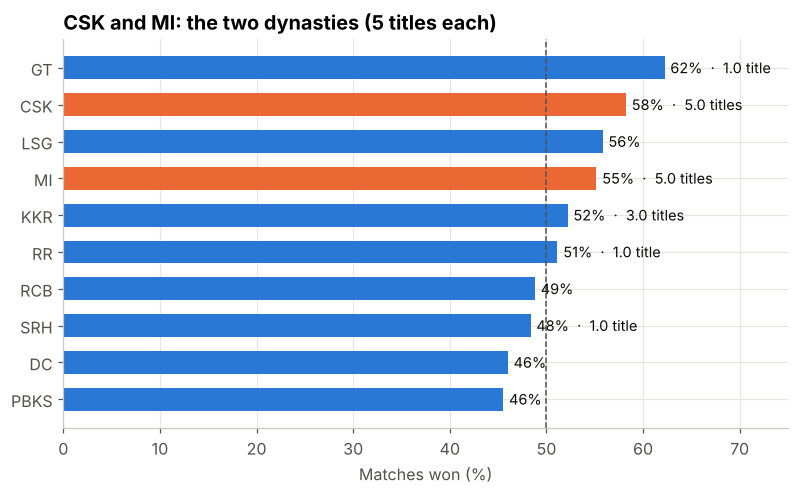

,played,won,win_pct,titles
team,,,,
GT,45,28,62.2,1
CSK,237,138,58.2,5
LSG,43,24,55.8,0
MI,261,144,55.2,5
KKR,251,131,52.2,3
RR,219,112,51.1,1
RCB,252,123,48.8,0
SRH,182,88,48.4,1
DC,250,115,46.0,0


In [3]:
finals = matches[matches.match_type == "Final"][["season", "winner_short", "bat_first_short", "bat_second_short",
                                                    "result", "result_margin"]]
titles = finals.winner_short.value_counts()
print("Titles:", titles.to_dict())

decided = matches[~matches.no_result & matches.winner.notna()]
games = pd.concat([decided[["season", "team1_short", "winner_short"]].rename(columns={"team1_short": "team"}),
                   decided[["season", "team2_short", "winner_short"]].rename(columns={"team2_short": "team"})])
games["won"] = games.team == games.winner_short
record = games.groupby("team").agg(played=("won", "size"), won=("won", "sum"))
record["win_pct"] = record.won / record.played * 100
record["titles"] = titles.reindex(record.index).fillna(0).astype(int)
record = record.loc[ipl.ACTIVE].sort_values("win_pct")

fig, ax = plt.subplots(figsize=(8.5, 4.6))
colors = [ORANGE if t in ("CSK", "MI") else BLUE for t in record.index]
ax.barh(record.index, record.win_pct, color=colors, height=0.62)
ax.axvline(50, color=MUTED, linestyle="--", linewidth=1)
for i, (t, r) in enumerate(record.iterrows()):
    label = f"{r.win_pct:.0f}%" + (f"  ·  {r.titles} title{'s' if r.titles > 1 else ''}" if r.titles else "")
    ax.text(r.win_pct + 0.6, i, label, va="center", color=INK, fontsize=9.5)
ax.set_xlim(0, 75)
ax.set_xlabel("Matches won (%)")
ax.set_title("CSK and MI: the two dynasties (5 titles each)")
save(fig, "teams")
plt.show()
record.sort_values("win_pct", ascending=False).round(1)

**CSK and MI have won 10 of 17 titles between them** and the best win rates (58% and 55%). Gujarat Titans win
the most often of all (62%), but they have only played since 2022.

## 4. Does the toss matter?

Commentators often call the toss "crucial". If it were, the toss winner should win clearly more than half the
time. A binomial test checks whether 50.8% is really different from a coin flip.

Toss winner won 50.8% of 1090 matches · binomial test p = 0.61
Won the toss and chose to bat: 45.4% · chose to field: 53.9% (chi-square p = 0.009)


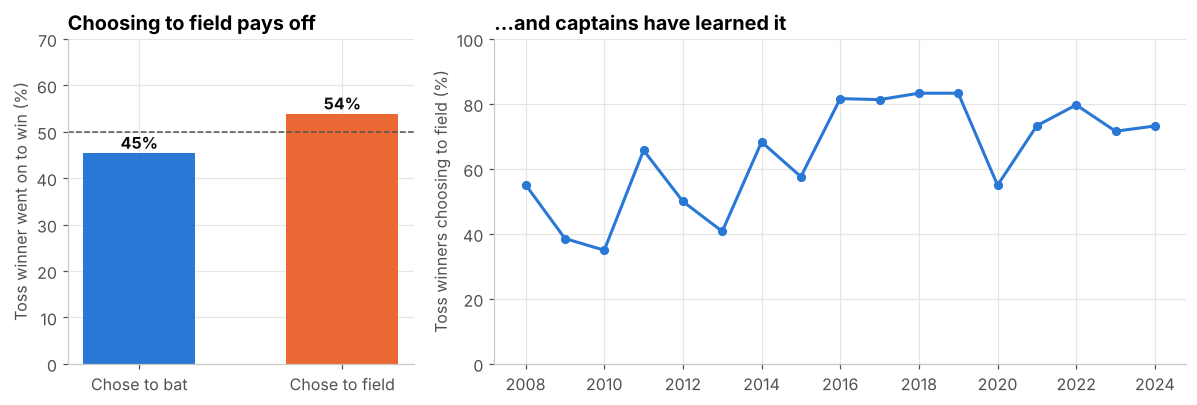

In [4]:
tw = decided.toss_winner_won.astype(bool)
test = stats.binomtest(tw.sum(), len(tw), 0.5)
print(f"Toss winner won {tw.mean():.1%} of {len(tw)} matches · binomial test p = {test.pvalue:.2f}")

by_choice = decided.groupby("toss_decision").toss_winner_won.agg(lambda s: s.astype(bool).mean() * 100)
table = pd.crosstab(decided.toss_decision, decided.toss_winner_won.astype(bool))
chi2, p_choice, _, _ = stats.chi2_contingency(table)
print(f"Won the toss and chose to bat: {by_choice['bat']:.1f}% · chose to field: {by_choice['field']:.1f}% "
      f"(chi-square p = {p_choice:.3f})")

field_share = matches.groupby("season").toss_decision.apply(lambda s: (s == "field").mean() * 100)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), gridspec_kw={"width_ratios": [1, 2]})
ax = axes[0]
ax.bar(["Chose to bat", "Chose to field"], by_choice[["bat", "field"]], color=[BLUE, ORANGE], width=0.55)
for i, v in enumerate(by_choice[["bat", "field"]]):
    ax.text(i, v + 1, f"{v:.0f}%", ha="center", color=INK, fontweight="bold")
ax.axhline(50, color=MUTED, linestyle="--", linewidth=1)
ax.set_ylim(0, 70)
ax.set_ylabel("Toss winner went on to win (%)")
ax.set_title("Choosing to field pays off")
ax = axes[1]
ax.plot(field_share.index, field_share.values, color=BLUE, linewidth=2, marker="o", markersize=5)
ax.set_ylim(0, 100)
ax.set_ylabel("Toss winners choosing to field (%)")
ax.set_title("...and captains have learned it")
ax.set_xticks(field_share.index[::2])
fig.tight_layout()
save(fig, "toss")
plt.show()

**Winning the toss on its own barely matters:** toss winners won 50.8% of matches, statistically the same as
a coin flip (p = 0.61). **What you do with it matters more:** toss winners who chose to field won 53.9%, against
45.4% for those who chose to bat (chi-square p ≈ 0.01). Captains have noticed: since 2016, about 3 in 4 choose
to field.

## 5. Chasing vs defending, ground by ground

Fielding first means chasing. Across the IPL, chasing teams win 54% of the time, but the ground changes the
answer completely.

Chasing team won 54.3% of 1076 matches
By season: {2008: 62, 2009: 54, 2010: 47, 2011: 56, 2012: 54, 2013: 50, 2014: 63, 2015: 43, 2016: 68, 2017: 55, 2018: 53, 2019: 61, 2020: 52, 2021: 63, 2022: 50, 2023: 45, 2024: 51}


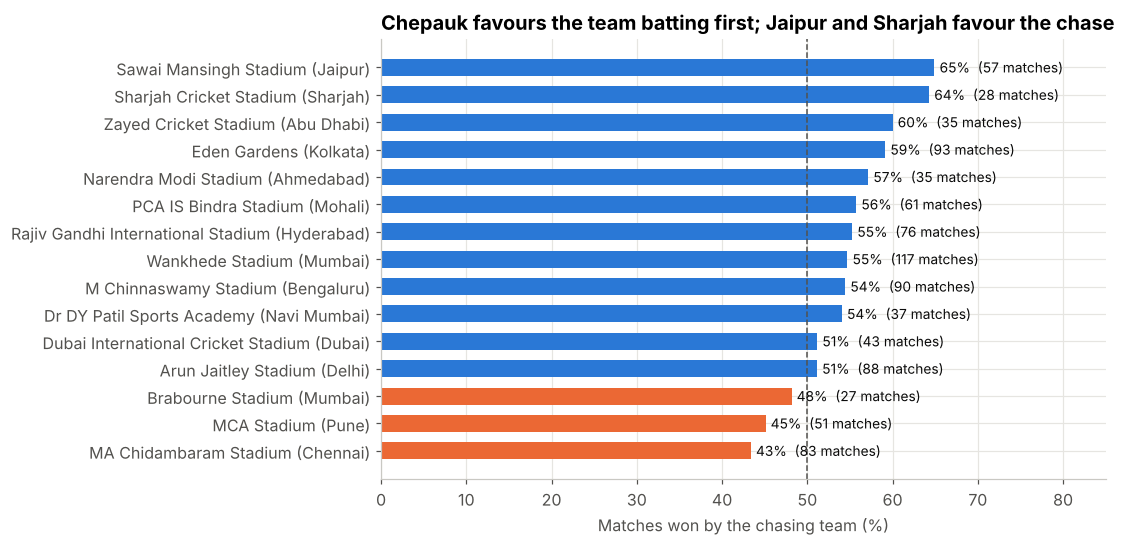

In [5]:
normal = decided[~decided.super_over]
print(f"Chasing team won {normal.chasing_won.astype(bool).mean():.1%} of {len(normal)} matches")
by_season = normal.groupby("season").chasing_won.agg(lambda s: s.astype(bool).mean() * 100)
print("By season:", by_season.round(0).astype(int).to_dict())

venue = (normal.groupby("venue").agg(matches=("match_id", "size"),
                                      chase=("chasing_won", lambda s: s.astype(bool).mean() * 100))
         .query("matches >= 25").sort_values("chase"))
venue["city"] = venue.index.map(ipl.VENUE_CITY)

fig, ax = plt.subplots(figsize=(8.5, 5.2))
colors = [ORANGE if v < 50 else BLUE for v in venue.chase]
labels = [f"{v} ({c})" if isinstance(c, str) else v for v, c in zip(venue.index, venue.city)]
ax.barh(labels, venue.chase, color=colors, height=0.62)
ax.axvline(50, color=MUTED, linestyle="--", linewidth=1)
for i, (v, n) in enumerate(zip(venue.chase, venue.matches)):
    ax.text(v + 0.6, i, f"{v:.0f}%  ({n} matches)", va="center", fontsize=9, color=INK)
ax.set_xlim(0, 85)
ax.set_xlabel("Matches won by the chasing team (%)")
ax.set_title("Chepauk favours the team batting first; Jaipur and Sharjah favour the chase")
save(fig, "chase_by_venue")
plt.show()

- **Chepauk (Chennai) is the hardest place to chase:** 43% of chases succeed. Spin and a slowing pitch help the
  team defending, which fits CSK's home strategy.
- **Jaipur (65%) and Sharjah (64%) are the easiest.** Bowling first there is the right call.
- In the Impact Player era, chasing got *harder*: chasing teams won 45% in 2023 and 51% in 2024, partly because
  first-innings totals jumped (next section).

## 6. The scoring revolution (and the Impact Player rule)

In 2023 the IPL introduced the **Impact Player** rule: each team can swap in a substitute mid-match, usually an
extra batter. The effect is clear in the data.

Average first-innings score: {2008: 162, 2009: 150, 2010: 165, 2011: 156, 2012: 158, 2013: 156, 2014: 163, 2015: 166, 2016: 164, 2017: 166, 2018: 172, 2019: 169, 2020: 170, 2021: 159, 2022: 171, 2023: 183, 2024: 190}
200+ innings: {2008: 11, 2009: 1, 2010: 9, 2011: 5, 2012: 5, 2013: 4, 2014: 9, 2015: 7, 2016: 6, 2017: 10, 2018: 15, 2019: 11, 2020: 13, 2021: 9, 2022: 18, 2023: 37, 2024: 41}


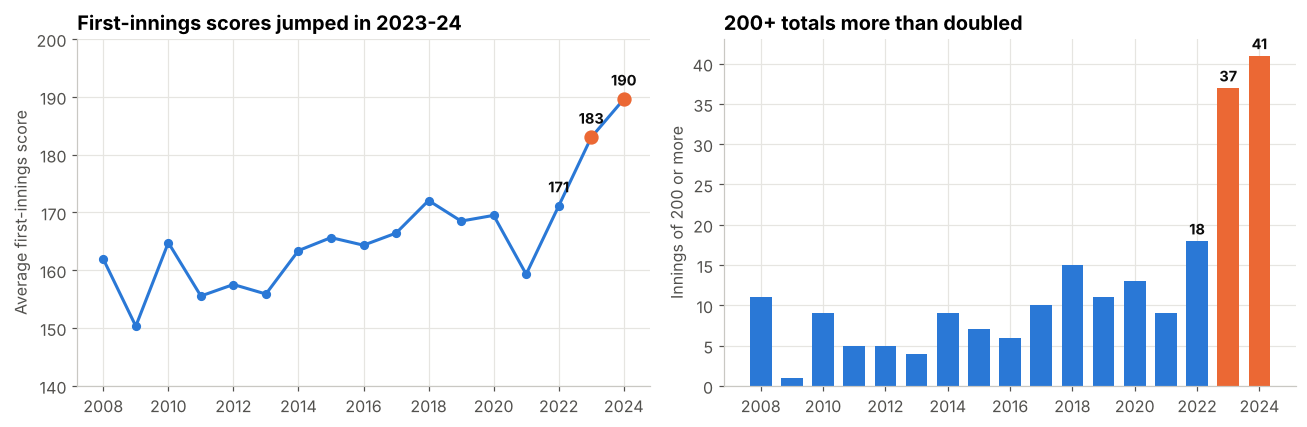

In [6]:
innings = (balls.groupby(["match_id", "inning", "season"])
           .agg(runs=("total_runs", "sum"), wickets=("wicket", "sum")).reset_index())
first = innings[innings.inning == 1].merge(matches[["match_id", "dls", "no_result"]], on="match_id")
first = first[~first.dls & ~first.no_result]
avg_first = first.groupby("season").runs.mean()
big = innings[innings.runs >= 200].groupby("season").size().reindex(avg_first.index, fill_value=0)
print("Average first-innings score:", avg_first.round(0).astype(int).to_dict())
print("200+ innings:", big.to_dict())

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
impact = avg_first.index >= 2023
ax = axes[0]
ax.plot(avg_first.index, avg_first.values, color=BLUE, linewidth=2, marker="o", markersize=5)
ax.scatter(avg_first.index[impact], avg_first.values[impact], color=ORANGE, s=70, zorder=3)
for y in (2022, 2023, 2024):
    ax.annotate(f"{avg_first[y]:.0f}", (y, avg_first[y]), xytext=(0, 9), textcoords="offset points",
                ha="center", fontsize=9.5, color=INK, fontweight="bold")
ax.set_ylim(140, 200)
ax.set_xticks(avg_first.index[::2])
ax.set_ylabel("Average first-innings score")
ax.set_title("First-innings scores jumped in 2023-24")
ax = axes[1]
ax.bar(big.index, big.values, color=[ORANGE if y >= 2023 else BLUE for y in big.index], width=0.7)
for y in (2022, 2023, 2024):
    ax.text(y, big[y] + 0.8, str(big[y]), ha="center", fontsize=9.5, fontweight="bold", color=INK)
ax.set_xticks(big.index[::2])
ax.set_ylabel("Innings of 200 or more")
ax.set_title("200+ totals more than doubled")
fig.tight_layout()
save(fig, "scoring")
plt.show()

phase                    Powerplay  Middle  Death
era                                              
2008-17                       7.52    7.56   9.68
2018-22                       7.95    7.85  10.09
2023-24 (Impact Player)       9.08    8.62  10.83


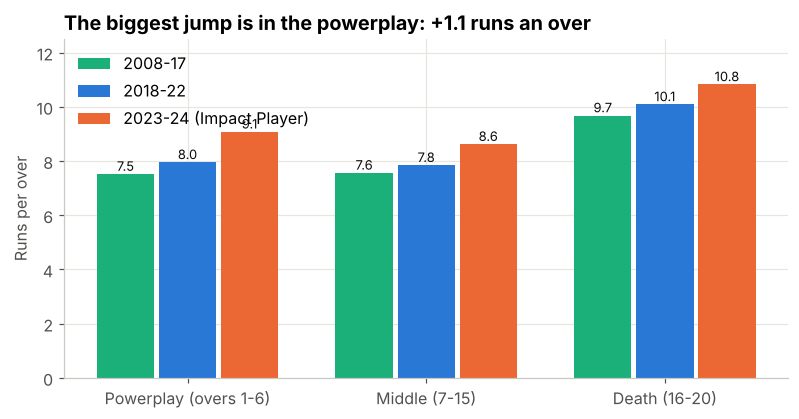

Sixes per match: {2008: 10.7, 2009: 8.9, 2010: 9.8, 2011: 8.8, 2012: 9.9, 2013: 8.9, 2014: 11.9, 2015: 11.7, 2016: 10.6, 2017: 11.9, 2018: 14.5, 2019: 13.1, 2020: 12.2, 2021: 11.4, 2022: 14.4, 2023: 15.2, 2024: 17.8}


In [7]:
era = np.select([balls.season >= 2023, balls.season >= 2018], ["2023-24 (Impact Player)", "2018-22"], "2008-17")
rr = (balls.assign(era=era).groupby(["era", "phase"], observed=True)
      .agg(runs=("total_runs", "sum"), legal=("legal", "sum")))
rr = (rr.runs / rr.legal * 6).unstack()[["Powerplay", "Middle", "Death"]]
print(rr.round(2))

fig, ax = plt.subplots(figsize=(8.5, 4))
x = np.arange(3)
for i, (name, color) in enumerate(zip(rr.index, [AQUA, BLUE, ORANGE])):
    bars = ax.bar(x + (i - 1) * 0.26, rr.loc[name], width=0.24, color=color, label=name)
    for xb, v in zip(x + (i - 1) * 0.26, rr.loc[name]):
        ax.text(xb, v + 0.12, f"{v:.1f}", ha="center", fontsize=8.5, color=INK)
ax.set_xticks(x, ["Powerplay (overs 1-6)", "Middle (7-15)", "Death (16-20)"])
ax.set_ylim(0, 12.5)
ax.set_ylabel("Runs per over")
ax.set_title("The biggest jump is in the powerplay: +1.1 runs an over")
ax.legend(frameon=False, loc="upper left")
save(fig, "phases")
plt.show()

sixes = balls.groupby("season").six.sum() / matches.groupby("season").size()
print("Sixes per match:", sixes.round(1).to_dict())

**The Impact Player rule changed the game.** Compared with 2018-22:

- Average first-innings score rose from about **170 to 190** (2024).
- **200+ innings went from 18 (2022) to 41 (2024).**
- Powerplay scoring rose from **7.9 to 9.1 runs an over**, the biggest jump of any phase.
- Sixes per match went from 14.4 (2022) to **17.8 (2024)**.

With an extra batter in hand, top orders attack from ball one. **A par score from before 2023 is now a losing
score.**

## 7. Batters: who scores, and how fast

                runs  balls  average  strike_rate  sixes
batter                                                  
V Kohli         8004   6065     38.7        132.0    273
S Dhawan        6769   5324     35.1        127.1    153
RG Sharma       6628   5054     29.7        131.1    281
DA Warner       6565   4697     40.5        139.8    236
SK Raina        5528   4043     32.5        136.7    203
MS Dhoni        5243   3812     39.1        137.5    252
AB de Villiers  5162   3403     39.7        151.7    251
CH Gayle        4965   3333     39.7        149.0    357
RV Uthappa      4952   3799     27.5        130.4    182
KD Karthik      4842   3577     26.3        135.4    161


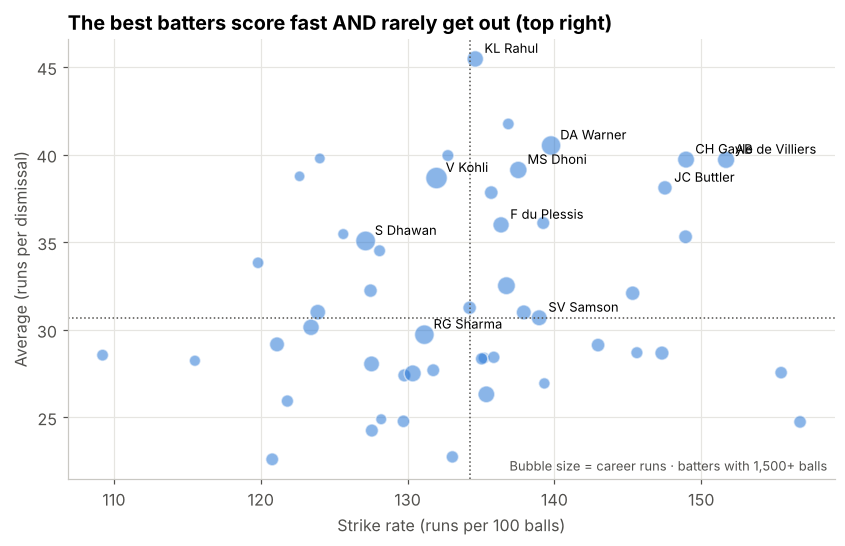

In [8]:
bf = balls[balls.faced]
bat = bf.groupby("batter", observed=True).agg(runs=("batter_runs", "sum"), balls=("faced", "sum"),
                                              fours=("four", "sum"), sixes=("six", "sum"))
outs = balls[balls.wicket].groupby("player_dismissed", observed=True).size()
bat["outs"] = outs.reindex(bat.index).fillna(0)
bat["strike_rate"] = bat.runs / bat.balls * 100
bat["average"] = bat.runs / bat.outs.replace(0, np.nan)
top = bat.sort_values("runs", ascending=False).head(10)
print(top[["runs", "balls", "average", "strike_rate", "sixes"]].round(1))

regular = bat[bat.balls >= 1500]
fig, ax = plt.subplots(figsize=(9, 5.2))
ax.scatter(regular.strike_rate, regular.average, s=regular.runs / 40, color=BLUE, alpha=0.55,
           edgecolor="white", linewidth=1)
for name in ["V Kohli", "AB de Villiers", "CH Gayle", "DA Warner", "KL Rahul", "JC Buttler",
             "RG Sharma", "MS Dhoni", "AD Russell", "SV Samson", "S Dhawan", "F du Plessis"]:
    if name in regular.index:
        r = regular.loc[name]
        ax.annotate(name, (r.strike_rate, r.average), xytext=(6, 4), textcoords="offset points", fontsize=8.5)
ax.axvline(regular.strike_rate.median(), color=MUTED, linestyle=":", linewidth=1)
ax.axhline(regular.average.median(), color=MUTED, linestyle=":", linewidth=1)
ax.set_xlabel("Strike rate (runs per 100 balls)")
ax.set_ylabel("Average (runs per dismissal)")
ax.set_title("The best batters score fast AND rarely get out (top right)")
ax.text(0.99, 0.02, "Bubble size = career runs · batters with 1,500+ balls", transform=ax.transAxes,
        ha="right", fontsize=8.5, color=MUTED)
save(fig, "batters")
plt.show()

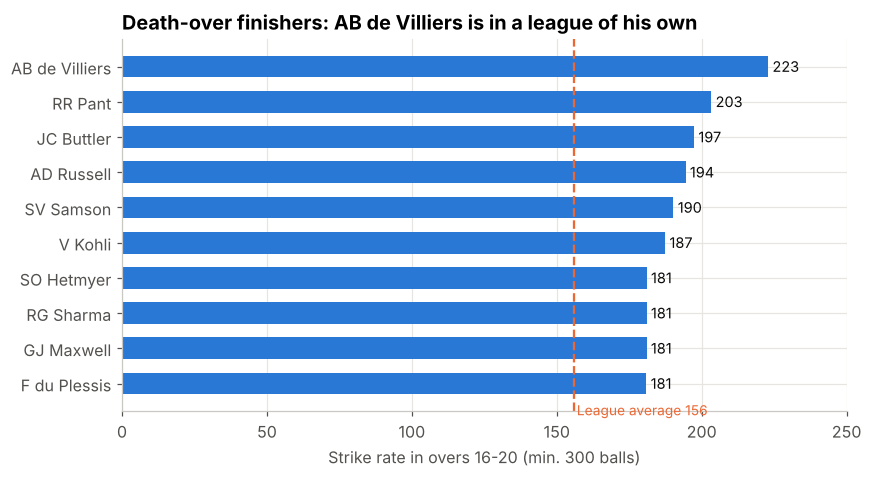

In [9]:
death = balls[(balls.phase == "Death") & balls.faced].groupby("batter", observed=True).agg(
    runs=("batter_runs", "sum"), balls=("faced", "sum"))
death = death[death.balls >= 300].assign(strike_rate=lambda d: d.runs / d.balls * 100)
death = death.sort_values("strike_rate").tail(10)
league_death_sr = balls[(balls.phase == "Death") & balls.faced].pipe(lambda d: d.batter_runs.sum() / len(d) * 100)

fig, ax = plt.subplots(figsize=(8.5, 4.4))
ax.barh(death.index, death.strike_rate, color=BLUE, height=0.62)
ax.axvline(league_death_sr, color=ORANGE, linestyle="--", linewidth=1.5)
ax.text(league_death_sr + 1, -0.9, f"League average {league_death_sr:.0f}", color=ORANGE, fontsize=9)
for i, v in enumerate(death.strike_rate):
    ax.text(v + 1.5, i, f"{v:.0f}", va="center", fontsize=9.5, color=INK)
ax.set_xlim(0, 250)
ax.set_xlabel("Strike rate in overs 16-20 (min. 300 balls)")
ax.set_title("Death-over finishers: AB de Villiers is in a league of his own")
save(fig, "death_batters")
plt.show()

- **Virat Kohli is the IPL's top run scorer (8,004)**, with an average near 39 at a strike rate of 132.
- **AB de Villiers scored at a strike rate of 223 in the death overs**, about 60 points above the league average.
- The scatter shows the trade-off between scoring fast and not getting out. The players in the top-right corner,
  like de Villiers, Gayle and Buttler, do both.

## 8. Bowlers: wickets, economy and the death overs

            wickets  economy  dot_pct  boundary_pct
bowler                                             
YS Chahal       205     7.84    33.91         14.17
PP Chawla       192     7.96    34.42         15.48
DJ Bravo        183     8.38    31.99         16.15
B Kumar         181     7.56    41.74         16.78
R Ashwin        180     7.12    34.31         11.47
SP Narine       180     6.73    38.50         11.56
A Mishra        174     7.38    35.15         12.55
SL Malinga      170     7.14    40.45         14.14

Correlation with economy · dot-ball %: -0.11 · boundary %: 0.84


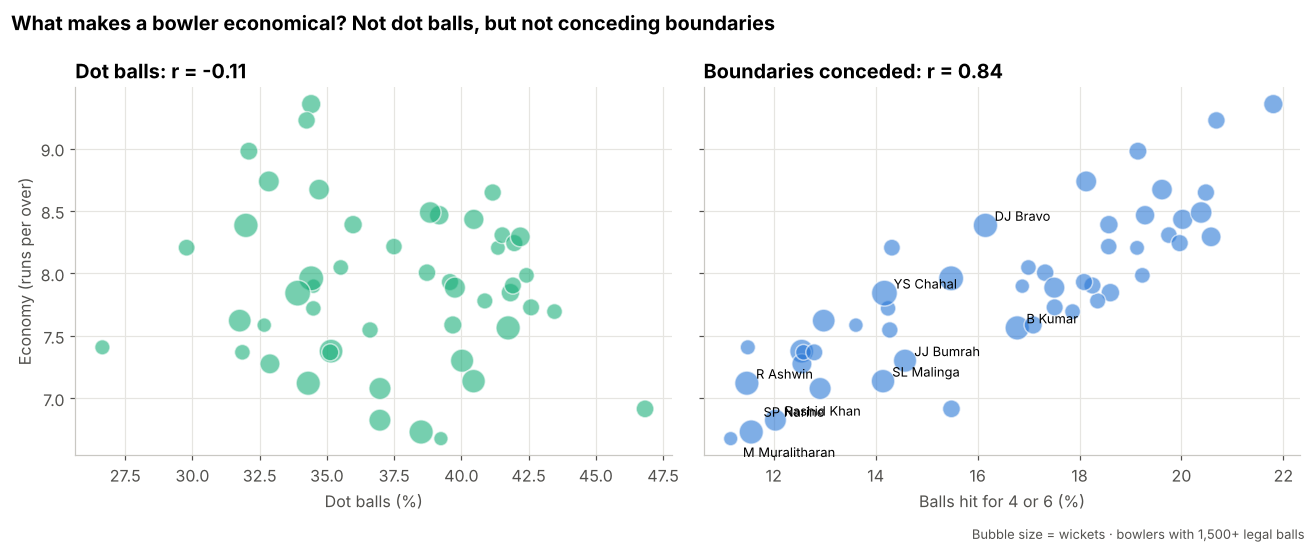

In [10]:
bowl = balls.groupby("bowler", observed=True).agg(runs=("bowler_runs", "sum"), balls=("legal", "sum"),
                                                   wickets=("bowler_wicket", "sum"), dots=("dot", "sum"),
                                                   fours=("four", "sum"), sixes=("six", "sum"))
bowl["economy"] = bowl.runs / bowl.balls * 6
bowl["dot_pct"] = bowl.dots / bowl.balls * 100
bowl["boundary_pct"] = (bowl.fours + bowl.sixes) / bowl.balls * 100
print(bowl.sort_values("wickets", ascending=False).head(8)[["wickets", "economy", "dot_pct", "boundary_pct"]].round(2))

regular = bowl[bowl.balls >= 1500]
r_dot = np.corrcoef(regular.dot_pct, regular.economy)[0, 1]
r_bnd = np.corrcoef(regular.boundary_pct, regular.economy)[0, 1]
print(f"\nCorrelation with economy · dot-ball %: {r_dot:.2f} · boundary %: {r_bnd:.2f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), sharey=True)
for ax, col, label, r in [(axes[0], "dot_pct", "Dot balls (%)", r_dot),
                          (axes[1], "boundary_pct", "Balls hit for 4 or 6 (%)", r_bnd)]:
    ax.scatter(regular[col], regular.economy, s=regular.wickets * 1.4, color=AQUA if col == "dot_pct" else BLUE,
               alpha=0.6, edgecolor="white", linewidth=1)
    ax.set_xlabel(label)
    ax.set_title(f"{'Dot balls' if col == 'dot_pct' else 'Boundaries conceded'}: r = {r:.2f}")
offsets = {"SP Narine": (8, 10), "M Muralitharan": (8, -12)}
for name in ["SP Narine", "R Ashwin", "Rashid Khan", "M Muralitharan", "JJ Bumrah", "B Kumar", "YS Chahal",
             "DJ Bravo", "SL Malinga"]:
    if name in regular.index:
        r = regular.loc[name]
        axes[1].annotate(name, (r.boundary_pct, r.economy), xytext=offsets.get(name, (6, 3)),
                         textcoords="offset points", fontsize=8.5)
axes[0].set_ylabel("Economy (runs per over)")
fig.suptitle("What makes a bowler economical? Not dot balls, but not conceding boundaries", x=0.01, ha="left",
             fontweight="bold", fontsize=13)
fig.text(0.99, -0.02, "Bubble size = wickets · bowlers with 1,500+ legal balls", ha="right", fontsize=8.5, color=MUTED)
fig.tight_layout()
save(fig, "bowlers")
plt.show()

In [11]:
death_avg = balls[balls.phase == "Death"].pipe(lambda d: d.total_runs.sum() / d.legal.sum() * 6)
dbowl = balls[balls.phase == "Death"].groupby("bowler", observed=True).agg(
    runs=("bowler_runs", "sum"), balls=("legal", "sum"), wickets=("bowler_wicket", "sum"))
dbowl = dbowl[dbowl.balls >= 600].assign(economy=lambda d: d.runs / d.balls * 6).sort_values("economy")
print(f"League run rate in overs 16-20: {death_avg:.1f}")
dbowl.head(8).round(2)

League run rate in overs 16-20: 10.0


,runs,balls,wickets,economy
bowler,,,,
SP Narine,1260,1021,73,7.40
SL Malinga,1464,1117,108,7.86
JJ Bumrah,1723,1247,91,8.29
DW Steyn,877,634,50,8.30
CH Morris,933,646,58,8.67
Z Khan,916,607,37,9.05
B Kumar,2074,1353,100,9.20
YS Chahal,953,613,59,9.33


- **Yuzvendra Chahal has the most wickets (205).**
- **A surprise:** dot balls barely predict how economical a bowler is (r = -0.11), but **boundaries conceded
  predict it very strongly (r = 0.84)**. Spinners like Narine, Ashwin, Rashid Khan and Muralitharan bowl fewer
  dots than fast bowlers but give away a boundary only about once every 9 balls, so they are the most
  economical. **For a captain: "stop the boundaries" matters more than "build dot-ball pressure".**
- **The best death bowlers:** Sunil Narine (7.4 an over in overs 16-20), Lasith Malinga (7.9) and Jasprit Bumrah
  (8.3), between 1.7 and 2.6 runs an over cheaper than the league's death-over rate of 10.0.

## 9. A ball-by-ball win-probability model

**Goal:** before every ball of a chase, estimate the chance that the chasing team wins.

**Data:** every legal ball of every normal chase (no D/L target, no super over), described by runs needed,
balls left, wickets left, the target and the era. That's 118,186 game states from 1,055 matches.

**A fair test:** I train on 2008-2021 and test on **2022-2024, seasons the model has never seen**, including
the high-scoring Impact Player years. One match gives about 110 similar rows, so cross-validation is also
**grouped by match**, so the model is never tested on a match it has partly seen.

In [12]:
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import brier_score_loss, log_loss, roc_auc_score
from sklearn.model_selection import GroupKFold, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler

states = wp.chase_states(matches, balls)
print(f"{len(states):,} game states from {states.match_id.nunique():,} chases · "
      f"chasing team won {states.groupby('match_id').chase_won.first().mean():.1%}")
train, test = states[states.season <= 2021], states[states.season >= 2022]
X_tr, y_tr, X_te, y_te = train[wp.FEATURES], train.chase_won, test[wp.FEATURES], test.chase_won

candidates = {
    "Baseline: required run rate only": make_pipeline(
        FunctionTransformer(wp.add_rates), ColumnTransformer([("s", StandardScaler(), ["required_rate"])]),
        LogisticRegression()),
    "Logistic regression": make_pipeline(
        FunctionTransformer(wp.add_rates),
        ColumnTransformer([("s", StandardScaler(), wp.FEATURES + ["required_rate", "current_rate"])]),
        LogisticRegression(max_iter=3000)),
    "Gradient boosting": make_pipeline(
        FunctionTransformer(wp.features),
        ColumnTransformer([("p", "passthrough", ["runs_needed", "balls_left", "wickets_left", "required_rate",
                                                 "need_per_wicket"])]),
        HistGradientBoostingClassifier(max_iter=150, learning_rate=0.05, max_depth=4, min_samples_leaf=1000,
                                       l2_regularization=5.0, random_state=26)),
    "Logistic regression + splines (final)": wp.make_model(),
}
rows, preds = [], {}
for name, model in candidates.items():
    cv = cross_val_score(model, X_tr, y_tr, groups=train.match_id, cv=GroupKFold(5), scoring="neg_log_loss")
    model.fit(X_tr, y_tr)
    p = model.predict_proba(X_te)[:, 1]
    preds[name] = p
    rows.append({"model": name, "CV log loss (2008-21)": -cv.mean(), "Test log loss (2022-24)": log_loss(y_te, p),
                 "Test Brier": brier_score_loss(y_te, p), "Test AUC": roc_auc_score(y_te, p)})
results = pd.DataFrame(rows).set_index("model").round(3)
results

118,186 game states from 1,055 chases · chasing team won 53.9%


,CV log loss (2008-21),Test log loss (2022-24),Test Brier,Test AUC
model,,,,
Baseline: required run rate only,0.489,0.502,0.164,0.839
Logistic regression,0.440,0.448,0.147,0.871
Gradient boosting,0.445,0.451,0.147,0.874
Logistic regression + splines (final),0.445,0.444,0.144,0.878


Lower log loss and Brier score are better (they reward confident *correct* probabilities). Higher AUC is better.
**Logistic regression with spline features** does best on the unseen seasons. Splines let a simple, explainable
model learn curves, such as "a required rate of 14 is far worse than 12, not just a bit worse".

**A model is only useful if its percentages mean what they say.** When it says 70%, the chasing team should win
about 70% of the time. Two checks: a calibration chart on the test seasons, and real match situations.

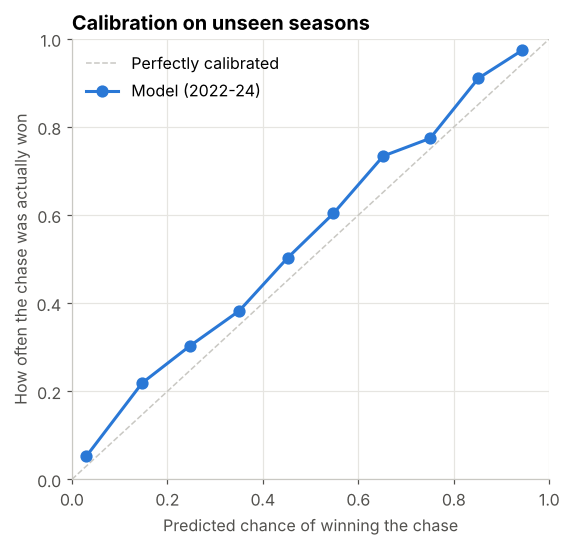

,Model,Actually won,Real cases
Situation,,,
"Need 10 off 6, 2 wickets left",54%,55%,11
"Need 10 off 6, 5 wickets left",81%,76%,41
"Need 30 off 18, 5 wickets left",64%,61%,51
"Need 60 off 36, 6 wickets left",51%,50%,118
"Need 16 off 12, 7 wickets left",87%,87%,31


In [13]:
final_p = preds["Logistic regression + splines (final)"]
bins = pd.cut(final_p, np.linspace(0, 1, 11), include_lowest=True)
cal = pd.DataFrame({"predicted": final_p, "actual": y_te.values}).groupby(bins, observed=True).agg(
    predicted=("predicted", "mean"), actual=("actual", "mean"), n=("actual", "size"))

fig, ax = plt.subplots(figsize=(5.6, 5.2))
ax.plot([0, 1], [0, 1], color="#c9c8c3", linestyle="--", linewidth=1, label="Perfectly calibrated")
ax.plot(cal.predicted, cal.actual, color=BLUE, linewidth=2, marker="o", markersize=7, label="Model (2022-24)")
ax.set_xlabel("Predicted chance of winning the chase")
ax.set_ylabel("How often the chase was actually won")
ax.set_title("Calibration on unseen seasons")
ax.set_xlim(0, 1); ax.set_ylim(0, 1)
ax.legend(frameon=False, loc="upper left")
save(fig, "calibration")
plt.show()

checks = []
for label, need, balls_left, wk, (n, b, w) in wp.SITUATIONS:
    s = states[states.runs_needed.between(*need) & (states.balls_left == balls_left) & states.wickets_left.between(*wk)]
    checks.append({"Situation": label, "Model": wp.probability(candidates["Logistic regression + splines (final)"], n, b, w, 180, False),
                   "Actually won": s.chase_won.mean(), "Real cases": len(s)})
checks = pd.DataFrame(checks).set_index("Situation")
checks[["Model", "Actually won"]] = (checks[["Model", "Actually won"]] * 100).round(0).astype(int).astype(str) + "%"
checks

The model's percentages line up with what really happened in matching situations, and it is close to the
diagonal on seasons it never saw. Where it drifts (it is a little too pessimistic about big chases in 2023-24),
the cause is the Impact Player rule: it was trained before chasing 200+ became common. **That's data drift, and
it's why the final model is retrained on all 17 seasons, with the era as a feature.**

**One more check, the last two overs**, where small samples make it easy to fool yourself. For example, in real IPL
chases that needed **2 off the last ball, the chasing team won 10 of 15**. That sounds high, but a single run means
a tie and a super over, and those matches are handled separately (they are not wins or losses for this model).
I compared a more complex gradient-boosting model with extra end-of-innings features against this one on the last
two overs of the unseen seasons, and it was **no more accurate**, so the simpler model stays.

In [14]:
import json
import joblib

final = wp.make_model().fit(states[wp.FEATURES], states.chase_won)
Path("../models").mkdir(exist_ok=True)
joblib.dump(final, "../models/win_model.joblib")
info = {"model": "Logistic regression + splines", "trained_on": "2008-2024 chases",
        "test_on_unseen_2022_24": results.loc["Logistic regression + splines (final)"].to_dict(),
        "baseline_auc": float(results.loc["Baseline: required run rate only", "Test AUC"]),
        "states": int(len(states)), "chases": int(states.match_id.nunique())}
Path("../models/model_info.json").write_text(json.dumps(info, indent=2))

for target in (160, 180, 200, 220):
    before = wp.probability(final, target, 120, 10, target, impact_era=False)
    after = wp.probability(final, target, 120, 10, target, impact_era=True)
    print(f"Chasing {target}: {before:.0%} before 2023 -> {after:.0%} in the Impact Player era")

Chasing 160: 58% before 2023 -> 66% in the Impact Player era
Chasing 180: 42% before 2023 -> 51% in the Impact Player era
Chasing 200: 28% before 2023 -> 36% in the Impact Player era
Chasing 220: 18% before 2023 -> 24% in the Impact Player era


### Replaying a final: 2019, Mumbai Indians vs Chennai Super Kings

MI made 149. CSK needed 150 and lost by **one run** off the last ball. Here is the model's view of that chase,
ball by ball.

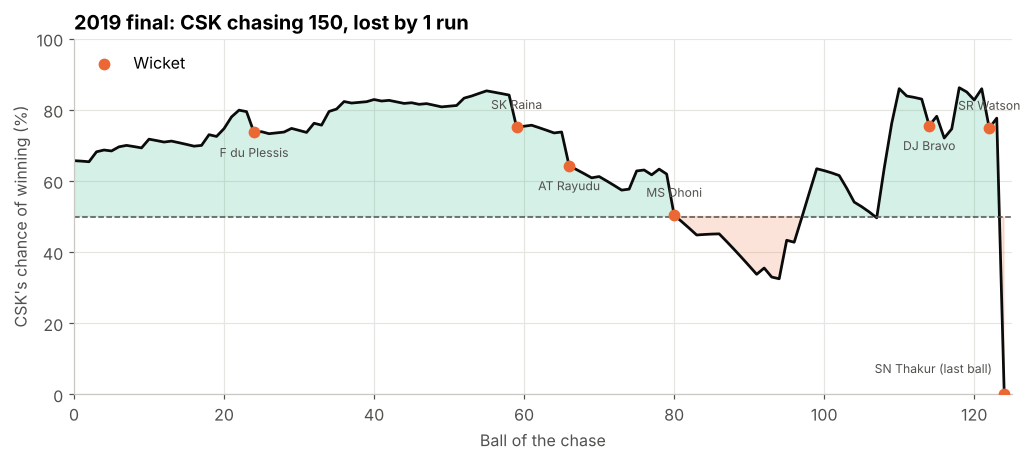

CSK's chance: 66% at the start, peak 86%, before the last ball 78%


In [15]:
final19 = matches[(matches.season == 2019) & (matches.match_type == "Final")].iloc[0]
mb = balls[balls.match_id == final19.match_id]
target = int(mb[mb.inning == 1].total_runs.sum() + 1)
start, w = wp.worm(final, mb, target, impact_era=False)

fig, ax = plt.subplots(figsize=(11, 4.2))
x = np.r_[0, w.ball_no]
y = np.r_[start, w.win_prob] * 100
ax.fill_between(x, 50, y, where=y >= 50, color=AQUA, alpha=0.18, interpolate=True)
ax.fill_between(x, 50, y, where=y < 50, color=ORANGE, alpha=0.18, interpolate=True)
ax.plot(x, y, color=INK, linewidth=1.8)
wk = w[w.wicket]
ax.scatter(wk.ball_no, wk.win_prob * 100, color=ORANGE, s=45, zorder=3, label="Wicket")
for k, (_, r) in enumerate(wk.iterrows()):
    out = mb[mb.inning == 2].iloc[int(r.ball_no) - 1].player_dismissed
    last = k == len(wk) - 1
    ax.annotate(str(out) + (" (last ball)" if last else ""), (r.ball_no, r.win_prob * 100),
                xytext=(-8, 14) if last else (0, -16 if k % 2 == 0 else 12), textcoords="offset points",
                ha="right" if last else "center", fontsize=8, color=MUTED)
ax.axhline(50, color=MUTED, linestyle="--", linewidth=1)
ax.set_ylim(0, 100)
ax.set_xlim(0, len(w) + 1)
ax.set_xlabel("Ball of the chase")
ax.set_ylabel("CSK's chance of winning (%)")
ax.set_title(f"2019 final: CSK chasing {target}, lost by 1 run")
ax.legend(frameon=False, loc="upper left")
save(fig, "worm_2019_final")
plt.show()
print(f"CSK's chance: {start:.0%} at the start, peak {w.win_prob.max():.0%}, before the last ball "
      f"{w.win_prob.iloc[-2]:.0%}")

## 10. Findings and recommendations

| # | Finding | Number |
|---|---|---|
| 1 | Winning the toss barely helps | 50.8% win rate (p = 0.61) |
| 2 | Choosing to field after winning the toss works better | 53.9% vs 45.4% (p ≈ 0.01) |
| 3 | The ground matters more than the toss | 43% of chases succeed at Chepauk vs 65% in Jaipur |
| 4 | The Impact Player rule made scoring explode | Average first innings 171 → 190, 200+ innings 18 → 41 |
| 5 | Powerplay scoring rose the most | 7.9 → 9.1 runs an over |
| 6 | Economy comes from not conceding boundaries, not from dot balls | r = 0.84 vs -0.11; best death bowlers 7.4-8.3 vs a 10.0 average |
| 7 | The win-probability model works on unseen seasons | AUC 0.88 vs 0.84 for required rate alone |

**Recommendations for a team strategist**

1. **Bowl first by default, except at slow grounds like Chepauk and Pune.** Decide by the ground's numbers, not
   habit.
2. **Re-set the par score.** Since 2023, defending 180 is a coin flip at best. Plan to reach 200+.
3. **Pay for powerplay hitters and death bowlers.** Those are the phases where matches swing most.
4. **Use the win-probability model during matches** to judge when to attack in a chase, and as a fair way to
   rate players by how much they moved their team's chances.

**Limitations:** this is public scorecard data, so it has no pitch reports, weather or player fitness. The win
model only covers chases. A first-innings model would need a "par score" for each ground and era.